In [2]:
import numpy
import pandas

from matplotlib import pyplot
import seaborn

In [3]:
titanic = pandas.read_csv("../conjuntos/titanic.csv")

titanic

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [7]:
100 * titanic["Age"].isna().sum() / titanic["Age"].count()

np.float64(24.789915966386555)

In [8]:
titanic[titanic["Age"] < 1]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
78,79,1,2,"Caldwell, Master. Alden Gates",male,0.83,0,2,248738,29.0000,NaN,S
305,306,1,1,"Allison, Master. Hudson Trevor",male,0.92,1,2,113781,151.5500,C22 C26,S
469,470,1,3,"Baclini, Miss. Helene Barbara",female,0.75,2,1,2666,19.2583,NaN,C
644,645,1,3,"Baclini, Miss. Eugenie",female,0.75,2,1,2666,19.2583,NaN,C
755,756,1,2,"Hamalainen, Master. Viljo",male,0.67,1,1,250649,14.5000,NaN,S
803,804,1,3,"Thomas, Master. Assad Alexander",male,0.42,0,1,2625,8.5167,NaN,C
831,832,1,2,"Richards, Master. George Sibley",male,0.83,1,1,29106,18.7500,NaN,S


In [15]:
x1 = titanic["Age"].copy()
x1[x1 < 0] = x1[x1 < 0] * 100

x1 = x1.fillna(x1.median()) # La edad del 50% de la población ordenada
# MEJOR -> Buscar el clúster de cada valor faltante y rellanar por la mediana de su clúster

x1

0      22.0
1      38.0
2      26.0
3      35.0
4      35.0
       ... 
886    27.0
887    19.0
888    28.0
889    26.0
890    32.0
Name: Age, Length: 891, dtype: float64

In [16]:
x2 = titanic["Fare"].copy()

x2

0       7.2500
1      71.2833
2       7.9250
3      53.1000
4       8.0500
        ...   
886    13.0000
887    30.0000
888    23.4500
889    30.0000
890     7.7500
Name: Fare, Length: 891, dtype: float64

<Axes: ylabel='Density'>

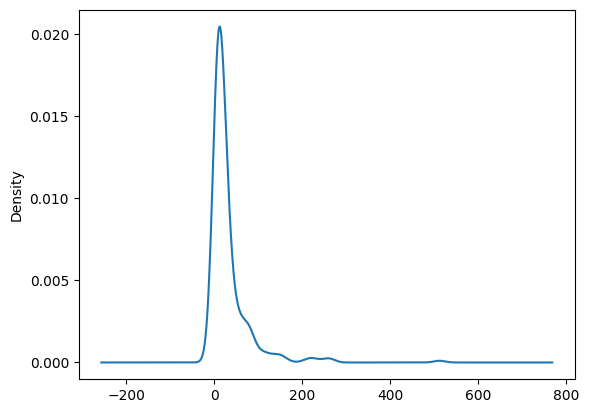

In [17]:
x2.plot.density()

<Axes: >

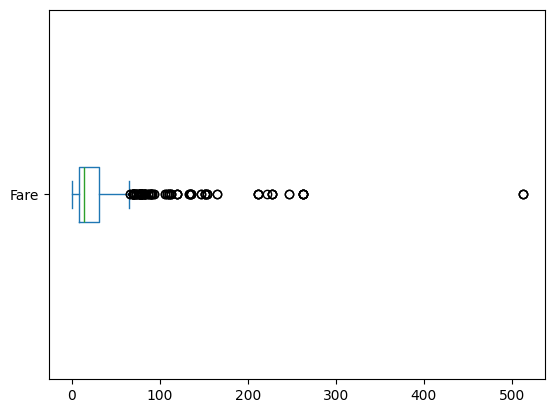

In [18]:
x2.plot.box(vert=False)

<Axes: >

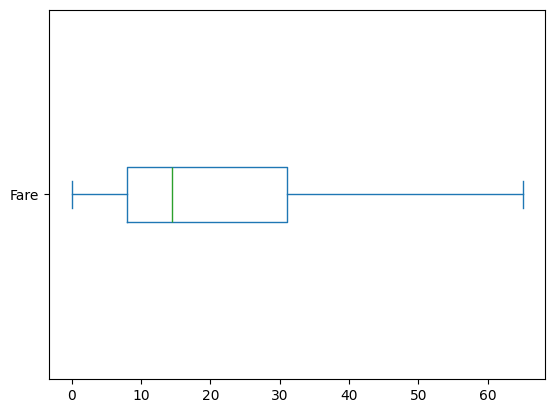

In [19]:
x2.plot.box(vert=False, showfliers=False)

In [20]:
x2.describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

<Axes: xlabel='0'>

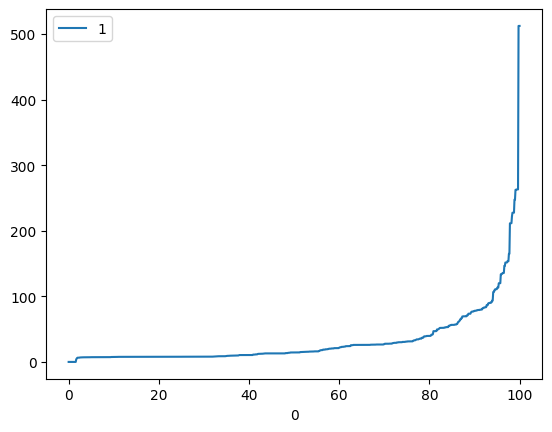

In [26]:
pandas.DataFrame([
    numpy.linspace(0, 100, 891),
    x2.sort_values()
]).T.set_index(0).plot.line()

In [ ]:
y = titanic["Survived"] # Continuo/Discreto

y # Cerrada / Logístico [0, 1]

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 891, dtype: int64

In [34]:
pandas.DataFrame([x1, x2, y]).T # Problema de Regresión

,Age,Fare,Survived
0,22.0,7.2500,0.0
1,38.0,71.2833,1.0
2,26.0,7.9250,1.0
3,35.0,53.1000,1.0
4,35.0,8.0500,0.0
...,...,...,...
886,27.0,13.0000,0.0
887,19.0,30.0000,1.0
888,28.0,23.4500,0.0
889,26.0,30.0000,1.0


In [48]:
# 2-características (x1, x2) continuas
# 1-respuesta (y) continua pero cerrada entre [0, 1] -> Problema de Clasificación

# 1. Encontrar la respuesta lineal (z)
# z - Es un predictor lineal que predice linealmente cuál es el valor combinado de (x1 y x2)
#     con pesos b0, (b1, b2) asociados a la fuerza de predicción de cada variable sobre la respuesta lineal

# z = b0 + b1 * x1 + b2 * x2

b0 = -15
b1 = 0.23
b2 = 0.98

# Combinación lineal de las variables -> Respuesta lineal
z = b0 + b1 * x1 + b2 * x2
z.name = "z"

pandas.DataFrame([x1, x2, y, z]).T

,Age,Fare,Survived,z
0,22.0,7.2500,0.0,-2.835000
1,38.0,71.2833,1.0,63.597634
2,26.0,7.9250,1.0,-1.253500
3,35.0,53.1000,1.0,45.088000
4,35.0,8.0500,0.0,0.939000
...,...,...,...,...
886,27.0,13.0000,0.0,3.950000
887,19.0,30.0000,1.0,18.770000
888,28.0,23.4500,0.0,14.421000
889,26.0,30.0000,1.0,20.380000


In [49]:
# 2. Modelo de predicción: yp(z) -> y
# Modelo logístico: yp(z) = e^z / (1 + e^z) = 1 / (1 + e^(-z)) | Sigmoide / Logístico

yp = numpy.exp(z) / (1 + numpy.exp(z))
yp.name = "yp"

pandas.DataFrame([x1, x2, y, z, yp]).T

,Age,Fare,Survived,z,yp
0,22.0,7.2500,0.0,-2.835000,0.055462
1,38.0,71.2833,1.0,63.597634,1.000000
2,26.0,7.9250,1.0,-1.253500,0.222095
3,35.0,53.1000,1.0,45.088000,1.000000
4,35.0,8.0500,0.0,0.939000,0.718898
...,...,...,...,...,...
886,27.0,13.0000,0.0,3.950000,0.981109
887,19.0,30.0000,1.0,18.770000,1.000000
888,28.0,23.4500,0.0,14.421000,0.999999
889,26.0,30.0000,1.0,20.380000,1.000000


In [50]:
pandas.DataFrame([y, yp]).T

,Survived,yp
0,0.0,0.055462
1,1.0,1.000000
2,1.0,0.222095
3,1.0,1.000000
4,0.0,0.718898
...,...,...
886,0.0,0.981109
887,1.0,1.000000
888,0.0,0.999999
889,1.0,1.000000


In [52]:
pandas.DataFrame([y.astype(int), (yp > 0.5).astype(int)]).T.groupby(["Survived", "yp"]).size().unstack()

yp,0,1
Survived,,
0,215,334
1,68,274


In [55]:
from sklearn.linear_model import LogisticRegression

modelo = LogisticRegression()

X = pandas.DataFrame([x1, x2]).T
y = titanic["Survived"]

modelo.fit(X, y)

# b0 = -0.47998092, b1 = -0.01681706, b2 = 0.01619514
modelo.intercept_, modelo.coef_

(array([-0.47998092]), array([[-0.01681706,  0.01619514]]))

In [56]:
b0 = -0.47998092
b1 = -0.01681706
b2 = 0.01619514

z = b0 + b1 * x1 + b2 * x2
z.name = "z"

yp = numpy.exp(z) / (1 + numpy.exp(z))
yp.name = "yp"

pandas.DataFrame([x1, x2, y, z, yp]).T.round(3)

,Age,Fare,Survived,z,yp
0,22.0,7.250,0.0,-0.733,0.325
1,38.0,71.283,1.0,0.035,0.509
2,26.0,7.925,1.0,-0.789,0.312
3,35.0,53.100,1.0,-0.209,0.448
4,35.0,8.050,0.0,-0.938,0.281
...,...,...,...,...,...
886,27.0,13.000,0.0,-0.724,0.327
887,19.0,30.000,1.0,-0.314,0.422
888,28.0,23.450,0.0,-0.571,0.361
889,26.0,30.000,1.0,-0.431,0.394


In [57]:
pandas.DataFrame([y, yp]).T

,Survived,yp
0,0.0,0.324637
1,1.0,0.508853
2,1.0,0.312410
3,1.0,0.448034
4,0.0,0.281263
...,...,...
886,0.0,0.326622
887,1.0,0.422224
888,0.0,0.360987
889,1.0,0.393799


In [58]:
pandas.DataFrame([y.astype(int), (yp > 0.5).astype(int)]).T.groupby(["Survived", "yp"]).size().unstack()

yp,0,1
Survived,,
0,506,43
1,264,78


In [59]:
M = pandas.DataFrame([y.astype(int), (yp > 0.5).astype(int)]).T.groupby(["Survived", "yp"]).size().unstack()

M

yp,0,1
Survived,,
0,506,43
1,264,78


In [60]:
R1 = M.divide(M.sum(axis=1), axis=0)
R2 = M.divide(M.sum(axis=0), axis=1)

In [62]:
100 * R1

yp,0,1
Survived,,
0,92.167577,7.832423
1,77.192982,22.807018


In [63]:
100 * R2

yp,0,1
Survived,,
0,65.714286,35.53719
1,34.285714,64.46281
